In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive
Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



yol = "/content/drive/MyDrive/data/data_v1.csv"
df = pd.read_csv("/content/drive/MyDrive/data/data_v1.csv")


df.shape


(2522362, 71)

In [ ]:



# df = senin veri setin

# 1) İstenmeyen sınıfları kaldır
df = df[~df["Label"].isin(["Heartbleed", "Infiltration"])].copy()


# 2) DoS alt türlerini tek sınıfta birleştir
dos_types = [
    "DoS Hulk",
    "DoS GoldenEye",
    "DoS slowloris",
    "DoS Slowhttptest"
]

df.loc[df["Label"].isin(dos_types), "Label"] = "DoS"




In [ ]:
web_mask = df["Label"].str.contains("Web Attack", na=False)
df.loc[web_mask, "Label"] = "Web Attacks"

In [ ]:
print(df["Label"].value_counts())

Label
BENIGN         2096484
DoS             193748
DDoS            128016
PortScan         90819
FTP-Patator       5933
SSH-Patator       3219
Web Attacks       2143
Bot               1953
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["Label_encoded"] = le.fit_transform(df["Label"])

# hangi sınıf hangi sayıya gitmiş görelim
print(dict(zip(le.classes_, le.transform(le.classes_))))

{'BENIGN': np.int64(0), 'Bot': np.int64(1), 'DDoS': np.int64(2), 'DoS': np.int64(3), 'FTP-Patator': np.int64(4), 'PortScan': np.int64(5), 'SSH-Patator': np.int64(6), 'Web Attacks': np.int64(7)}


In [ ]:
df["Label"] = df["Label_encoded"]

In [ ]:

df.drop(columns=["Label_encoded"], inplace=True)

In [ ]:
df.shape

(2522315, 71)

In [ ]:
import pandas as pd
import numpy as np
import sklearn

print("pandas version:", pd.__version__)
print("numpy version:", np.__version__)
print("scikit-learn version:", sklearn.__version__)

pandas version: 2.2.2
numpy version: 2.0.2
scikit-learn version: 1.6.1


In [ ]:
corr_matris = df.corr()

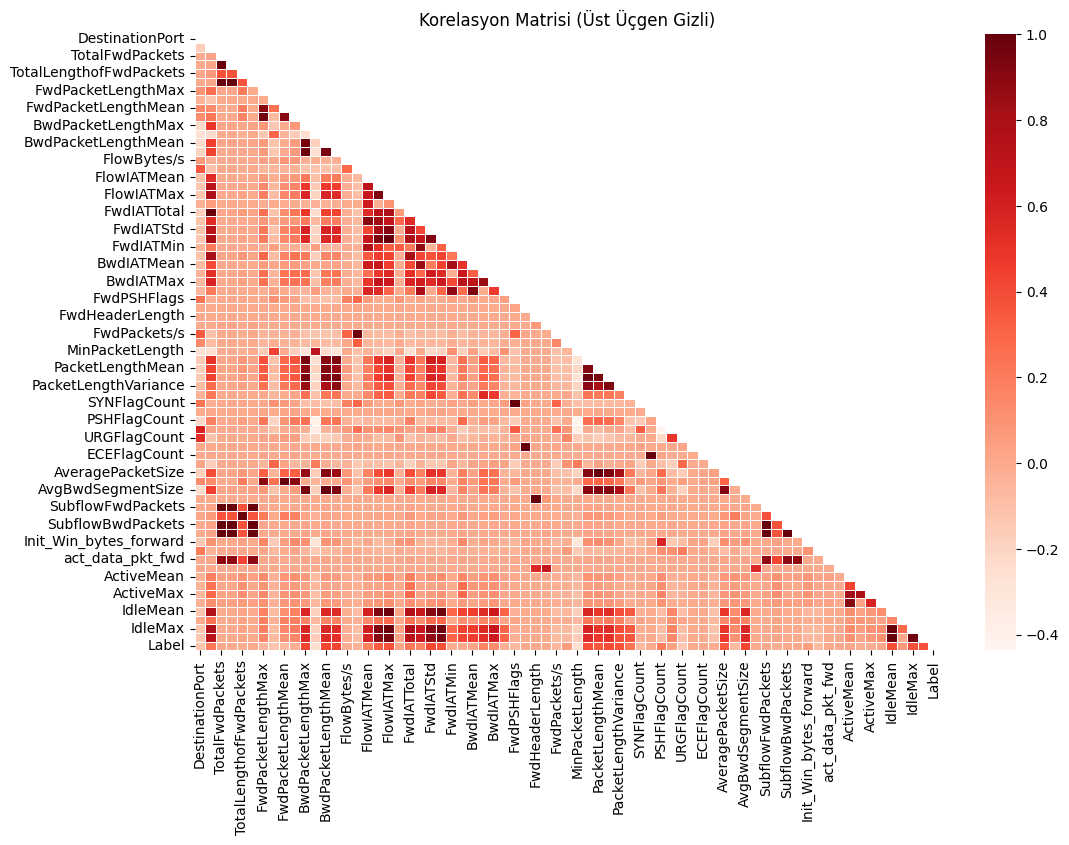

In [ ]:


mask = np.triu(np.ones_like(corr_matris, dtype=bool))

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matris,
    mask=mask,
    cmap="Reds",
    annot=False,
    linewidths=0.5
)

plt.title("Korelasyon Matrisi ")
plt.show()

In [ ]:
import numpy as np

corr_matris = df.corr(numeric_only=True)

# üst üçgen (tekrarları önlemek için)
upper = corr_matris.where(np.triu(np.ones(corr_matris.shape), k=1).astype(bool))

threshold = 1.0

print("📌 %95 üstü korelasyonlu feature çiftleri:\n")

for col in upper.columns:
    high_corr = upper[col][upper[col].abs() == threshold]

    for idx, value in high_corr.items():
        print(f"{col}  <--->  {idx}  | corr: {value:.3f}")

📌 %95 üstü korelasyonlu feature çiftleri:

SYNFlagCount  <--->  FwdPSHFlags  | corr: 1.000
CWEFlagCount  <--->  FwdURGFlags  | corr: 1.000
AvgFwdSegmentSize  <--->  FwdPacketLengthMean  | corr: 1.000
FwdHeaderLength.1  <--->  FwdHeaderLength  | corr: 1.000
SubflowFwdPackets  <--->  TotalFwdPackets  | corr: 1.000
SubflowBwdPackets  <--->  TotalBackwardPackets  | corr: 1.000


In [ ]:
drop_corr1 = [
    'SYNFlagCount',
    'CWEFlagCount',
    'AvgFwdSegmentSize',
    'FwdHeaderLength.1',
    'SubflowFwdPackets',
    'SubflowBwdPackets'
]


df = df.drop(columns=drop_corr1)

In [ ]:
df.shape

(2522315, 65)

In [ ]:
print(df["Label"].nunique())

8


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer

# Feature ve target ayır
X = df.drop(columns=["Label"])
y = df["Label"]

# Sadece sayısal feature'lar
X = X.select_dtypes(include=["number"])


# =========================
# 1. Stratified Train-Test Split
# =========================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


# =========================
# 2. Quantile Transformer
# =========================

qt = QuantileTransformer(
    output_distribution="normal",
    random_state=42
)

# sadece train üzerinde fit
X_train_scaled = qt.fit_transform(X_train)

# testte sadece transform
X_test_scaled = qt.transform(X_test)


# =========================
# 3. Kontrol
# =========================

print("Train transformed:", X_train_scaled.shape)
print("Test transformed:", X_test_scaled.shape)

Train shape: (1765620, 64)
Test shape: (756695, 64)
Train transformed: (1765620, 64)
Test transformed: (756695, 64)


In [ ]:

import os

save_path = "/content/drive/MyDrive/data/ai-ready-data"

os.makedirs(save_path, exist_ok=True)











# Train dataframe
train_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
train_df["Label"] = y_train.reset_index(drop=True)

# Test dataframe
test_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)
test_df["Label"] = y_test.reset_index(drop=True)

# Drive'a kaydet
train_df.to_csv(f"{save_path}/train_scaled.csv", index=False)
test_df.to_csv(f"{save_path}/test_scaled.csv", index=False)